# Swiss transmission grid: power flow and OPF

This notebook builds the Swiss 220/380 kV grid from public data, fills it with one hour of measured load, production and cross-border exchange, and runs:

1. an AC power flow with the measured production,
2. a DC optimal power flow (OPF) that finds the cheapest Swiss dispatch within the line limits,
3. an AC power flow on the OPF result.

The first run downloads about 60 MB and takes about 2 minutes. Later runs read from `data/`.

In [1]:
import copy
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.collections import LineCollection

import data
import network

## 1. Build the grid

Lines and transformers come from OpenStreetMap (PyPSA-Eur). Every Swiss power plant from the federal register is connected to its nearest substation. Each foreign substation at the border gets one injection for the exchange with that country.

In [2]:
net = network.build()
pd.Series({
    "Swiss substations": (net.bus.zone == "CH").sum(),
    "border substations": (net.bus.zone != "CH").sum(),
    "lines": len(net.line),
    "transformers": len(net.trafo),
    "installed capacity GW": net.sgen.capacity_mw[net.sgen.type != "Border"].sum() / 1000,
}).round(1)

Swiss substations        186.0
border substations        24.0
lines                    253.0
transformers              34.0
installed capacity GW     25.7
dtype: float64

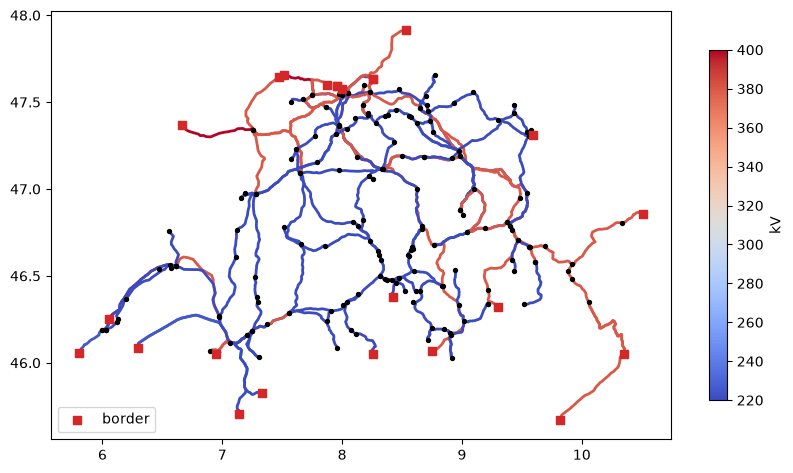

In [3]:
def draw(net, values, label, cmap="viridis"):
    fig, ax = plt.subplots(figsize=(10, 6.5))
    lines = ax.add_collection(LineCollection(net.line.coords, array=values, cmap=cmap, linewidths=2))
    border = net.bus.zone != "CH"
    ax.scatter(net.bus.lon[~border], net.bus.lat[~border], s=8, color="k", zorder=3)
    ax.scatter(net.bus.lon[border], net.bus.lat[border], s=40, marker="s", color="tab:red", zorder=3, label="border")
    ax.autoscale()
    ax.set_aspect(1.45)
    ax.legend(loc="lower left")
    fig.colorbar(lines, ax=ax, shrink=0.7, label=label)


draw(net, net.bus.vn_kv[net.line.from_bus].to_numpy(), "kV", cmap="coolwarm")

## 2. Pick an hour

- Load per canton and the exchange with each neighbour come from Swissgrid.
- Production per type comes from Energy-Charts, scaled to the Swissgrid total.
- Inside a canton the load is split equally over its substations. Inside a type, production is split by installed capacity.

In [4]:
YEAR = 2025
HOUR = pd.Timestamp("2025-01-15 18:00", tz="Europe/Zurich")

swissgrid = data.swissgrid(YEAR)
generation = data.generation(YEAR)
network.set_hour(net, swissgrid, generation, HOUR)

plants = net.sgen.type != "Border"
pd.Series({
    "load MW": net.load.p_mw.sum(),
    "production MW": net.sgen.p_mw[plants].sum(),
    "net import MW": net.sgen.p_mw[~plants].sum(),
}).round(0)

load MW           9677.0
production MW    12253.0
net import MW    -2570.0
dtype: float64

## 3. AC power flow

Newton-Raphson with the measured production. The slack is one border substation; it covers the losses and the small gap in the data.

In [5]:
network.run_power_flow(net)
power_flow = network.summary(net)
power_flow

production MW  Hydro run-of-river    1832.93
               Hydro storage         7097.71
               Nuclear               2853.44
               Others                 438.33
               Solar                    0.00
               Wind                    30.34
import MW      AT                    -909.75
               DE                   -2286.50
               FR                    -205.87
               IT                     832.42
               slack                   98.08
grid           load MW               9677.11
               losses MW              104.01
               max line loading %      64.84
               min voltage pu           0.92
dtype: float64

In [6]:
lines = net.line[["name"]].assign(loading_percent=net.res_line.loading_percent, p_mw=net.res_line.p_from_mw)
print(f"voltage {net.res_bus.vm_pu.min():.3f} to {net.res_bus.vm_pu.max():.3f} pu, losses {net.res_line.pl_mw.sum():.0f} MW")
lines.sort_values("loading_percent", ascending=False).head(10).round(1)

voltage 0.920 to 1.051 pu, losses 102 MW


,name,loading_percent,p_mw
8,merged_relation/5978223:a-220+1,64.8,-316.1
248,way/927740824-220,50.4,241.2
243,way/76706345-220,50.1,-252.5
2,merged_relation/14096018:b-380+5,50.0,-787.8
94,relation/5435444:b-220,46.7,-229.9
93,relation/5435443:b-220,46.7,-229.9
95,relation/5462443-220,45.2,-201.4
100,relation/5552980-220,44.0,-208.6
115,relation/5645841-220,41.5,-197.0
73,merged_way/720907970:b-220+2,41.2,198.0


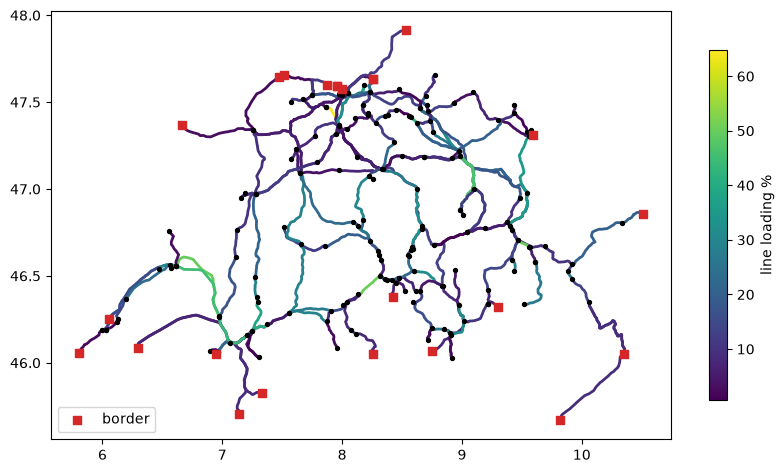

In [7]:
draw(net, net.res_line.loading_percent.to_numpy(), "line loading %")

## 4. DC optimal power flow

The OPF keeps the load and the exchange with each neighbour. It chooses which Swiss plants produce, at the lowest cost, without any line or transformer above 100 %.

- Storage hydro can produce up to its installed capacity.
- All other plants can produce up to what they produced in this hour.
- Costs per MWh are in `network.COST`.

In [8]:
network.COST

{'Solar': 0.0,
 'Wind': 0.0,
 'Hydro run-of-river': 1.0,
 'Nuclear': 5.0,
 'Hydro storage': 30.0,
 'Others': 60.0}

In [9]:
opf = network.run_opf(copy.deepcopy(net))
dc_result = network.summary(opf)
print(f"highest line loading {opf.res_line.loading_percent.max():.1f} %")

highest line loading 68.3 %


Check the OPF dispatch with an AC power flow:

In [10]:
network.run_power_flow(opf)
pd.DataFrame({"measured, AC": power_flow, "OPF, DC": dc_result, "OPF, AC check": network.summary(opf)})

measured, AC  OPF, DC  OPF, AC check
production MW Hydro run-of-river       1832.93  1832.93        1832.93
              Hydro storage            7097.71  7528.61        7528.61
              Nuclear                  2853.44  2853.44        2853.44
              Others                    438.33     0.00           0.00
              Solar                       0.00     0.00           0.00
              Wind                       30.34    30.34          30.34
import MW     AT                       -909.75  -909.75        -909.75
              DE                      -2286.50 -2286.50       -2286.50
              FR                       -205.87  -205.87        -205.87
              IT                        832.42   832.42         832.42
              slack                      98.08     1.50         117.11
grid          load MW                  9677.11  9677.11        9677.11
              losses MW                 104.01     0.00         115.61
              max line loading %         64.84    68.29          67.67
              min voltage pu              0.92     1.00           0.91

## 5. Try a weaker grid

Lower the line limit to 60 % and run the OPF again. To keep every line below the limit, the OPF must move production to other substations.

In [11]:
weak = copy.deepcopy(net)
weak.line["max_loading_percent"] = 60
network.run_opf(weak)
moved = (weak.sgen.p_mw - opf.sgen.p_mw).abs().sum() / 2
print(f"highest line loading {weak.res_line.loading_percent.max():.1f} %, {moved:.0f} MW moved between substations")
pd.DataFrame({"limit 100 %": dc_result, "limit 60 %": network.summary(weak)})

highest line loading 60.0 %, 1273 MW moved between substations


limit 100 %  limit 60 %
production MW Hydro run-of-river      1832.93     1832.93
              Hydro storage           7528.61     7536.28
              Nuclear                 2853.44     2808.75
              Others                     0.00       36.20
              Solar                      0.00        0.00
              Wind                      30.34       30.34
import MW     AT                      -909.75     -909.75
              DE                     -2286.50    -2286.50
              FR                      -205.87     -205.87
              IT                       832.42      832.42
              slack                      1.50        2.32
grid          load MW                 9677.11     9677.11
              losses MW                  0.00        0.00
              max line loading %        68.29       60.00
              min voltage pu             1.00        1.00

If the OPF raises `OPFNotConverged`, no dispatch can meet the limits with the measured exchange (for example at 40 %).

## 6. Two years, hour by hour

`network.run_hours` repeats steps 2 to 4 for every hour, in parallel on all CPU cores. Hours where the solver fails are left out.

The first run takes about 15 minutes (AC power flow and OPF). The results are saved in `data/`, so later runs load them in seconds.

In [12]:
YEARS = [2024, 2025]
swissgrid = pd.concat([data.swissgrid(y) for y in YEARS])
generation = pd.concat([data.generation(y) for y in YEARS])
hours = swissgrid.index.intersection(generation.index)


def run_cached(method):
    path = data.DATA / f"results_{method}_{YEARS[0]}_{YEARS[-1]}.pkl"
    if not path.exists():
        pd.to_pickle(network.run_hours(net, swissgrid, generation, hours, method), path)
    return pd.read_pickle(path)


ac_hours, ac_loading = run_cached("ac")
opf_hours, opf_loading = run_cached("opf")
print(f"{len(hours)} hours: AC power flow converged in {len(ac_hours)}, OPF found a dispatch in {len(opf_hours)}")

17544 hours: AC power flow converged in 17512, OPF found a dispatch in 16137


Monthly mean production per type, against the load:

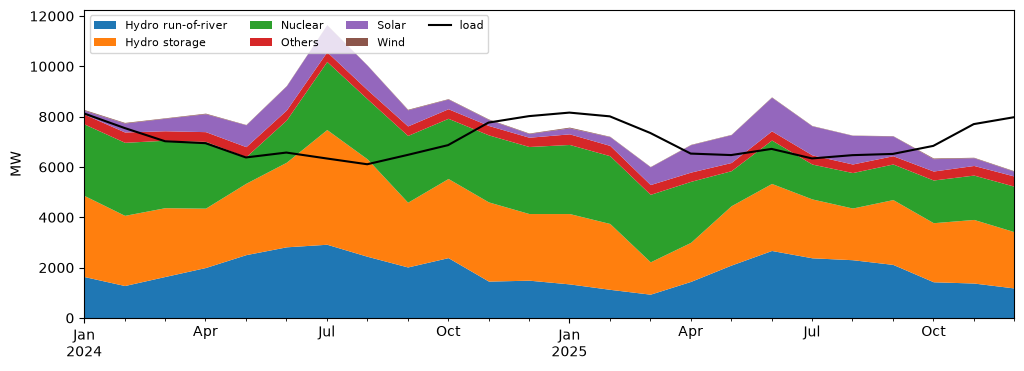

In [13]:
ax = ac_hours["production MW"].resample("MS").mean().plot.area(figsize=(12, 4), ylabel="MW", linewidth=0)
ac_hours[("grid", "load MW")].resample("MS").mean().plot(ax=ax, color="k", label="load")
ax.legend(loc="upper left", ncol=4, fontsize=8);

Duration curve of the most loaded line in each hour. Above 100 %, the measured dispatch overloads a line in this model. The OPF keeps every line at or below 100 %, but only in the hours where it finds a dispatch.

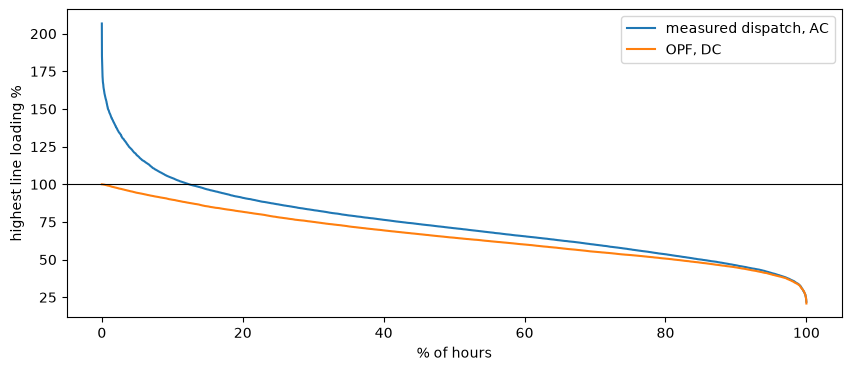

In [14]:
fig, ax = plt.subplots(figsize=(10, 4))
for label, result in {"measured dispatch, AC": ac_hours, "OPF, DC": opf_hours}.items():
    worst = np.sort(result[("grid", "max line loading %")].to_numpy())[::-1]
    ax.plot(np.linspace(0, 100, len(worst)), worst, label=label)
ax.axhline(100, color="k", lw=0.8)
ax.set(xlabel="% of hours", ylabel="highest line loading %")
ax.legend();

The lines that are most often heavily loaded with the measured dispatch:

In [15]:
pd.DataFrame({
    "hours above 80 %": (ac_loading > 80).mean() * 100,
    "P95 loading %": ac_loading.quantile(0.95),
    "max loading %": ac_loading.max(),
}).sort_values("hours above 80 %", ascending=False).head(10).round(1)

,hours above 80 %,P95 loading %,max loading %
name,,,
way/1200670020-380,29.6,119.0,206.8
way/927740824-220,6.4,82.2,112.1
way/208560300-220,0.8,67.8,103.4
relation/5462443-220,0.6,51.3,129.0
way/208625022-380,0.4,59.7,103.5
merged_way/207991756-380+3,0.4,59.3,103.3
merged_way/209411609-220+1,0.2,53.7,100.9
way/208560302-220,0.2,62.3,91.0
way/255353868-220,0.1,49.3,95.5


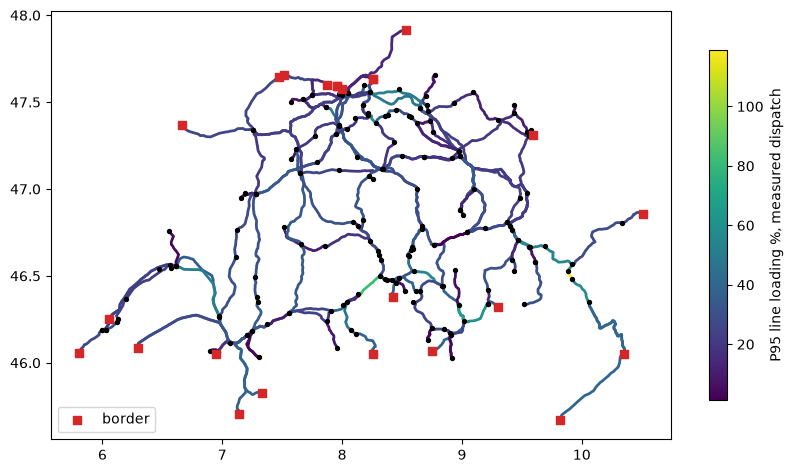

In [16]:
draw(net, ac_loading.quantile(0.95)[net.line.name].to_numpy(), "P95 line loading %, measured dispatch")

Mean production per type, measured and with the OPF (only the hours where the OPF found a dispatch):

In [17]:
common = ac_hours.index.intersection(opf_hours.index)
pd.DataFrame({"measured": ac_hours.loc[common, "production MW"].mean(),
              "OPF": opf_hours.loc[common, "production MW"].mean()}).round(0)

,measured,OPF
Hydro run-of-river,1918.0,1918.0
Hydro storage,2663.0,3036.0
Nuclear,2137.0,2137.0
Others,376.0,0.0
Solar,687.0,687.0
Wind,17.0,17.0
